In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from collections import Counter

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)
print("GPU tersedia    :", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)

PyTorch version: 2.15.0+cpu
GPU tersedia    : False
Device yang digunakan: cpu


In [2]:
df = pd.read_csv("../pertemuan-06/dataset_preprocessed.csv")

# Sesuaikan nama kolom dengan dataset masing-masing
text_column = "processed_text"
# label_column = "processed_text" TIDAK BOLEH dipakai ulang, dan kolom label memang tidak ada  # sesuaikan

df = df.dropna(subset=[text_column]) # hanya teks, tanpa label
df = df.reset_index(drop=True)

print(f"Jumlah data: {len(df)}")
# Baris distribusi label dihapus karena tidak ada kolom label

Jumlah data: 8926


In [3]:
def build_vocab(texts, max_vocab=10000, min_freq=2):
    counter = Counter()
    for text in texts:
        tokens = str(text).split()
        counter.update(tokens)

    # Tambahkan token khusus
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word, count in counter.most_common(max_vocab):
        if count >= min_freq:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(df[text_column])
print(f"Ukuran vocabulary: {len(vocab)}")

Ukuran vocabulary: 4979


In [4]:
def text_to_indices(text, vocab, max_len=100):
    tokens = str(text).split()[:max_len]
    indices = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    # Padding
    if len(indices) < max_len:
        indices += [vocab["<PAD>"]] * (max_len - len(indices))
    return indices

# Encode label (TIDAK ADA KOLOM LABEL)
# le = LabelEncoder()
# labels = le.fit_transform(df[label_column])
# num_classes = len(le.classes_)
# print(f"Kelas label: {le.classes_}")
# print(f"Jumlah kelas: {num_classes}")

MAX_LEN = 100
X = [text_to_indices(text, vocab, MAX_LEN) for text in df[text_column]]

print(f"Jumlah data terenkode: {len(X)}")
print(f"Panjang setiap urutan: {len(X[0])}")

Jumlah data terenkode: 8926
Panjang setiap urutan: 100


In [5]:
class TextDataset(Dataset):
    def __init__(self, texts): # tanpa labels
        self.texts = torch.LongTensor(texts)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx] # hanya kembalikan teks

# Split data
X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

train_dataset = TextDataset(X_train)
test_dataset = TextDataset(X_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train: {len(train_dataset)} | Test: {len(test_dataset)}")

Train: 7140 | Test: 1786


In [6]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx=0):
        super(RNNClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, hidden_dim)  # sesuaikan tanpa kelas
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        output, hidden = self.rnn(embedded)
        # Gunakan hidden state terakhir
        out = self.fc(self.dropout(hidden[-1]))
        return out

In [7]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx=0):
        super(LSTMClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3
        )
        self.fc = nn.Linear(hidden_dim, hidden_dim)  # sesuaikan tanpa kelas
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        output, (hidden, cell) = self.lstm(embedded)
        out = self.fc(self.dropout(hidden[-1]))
        return out

In [8]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, pad_idx=0):
        super(GRUClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(
            embed_dim, hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3
        )
        self.fc = nn.Linear(hidden_dim, hidden_dim)  # sesuaikan tanpa kelas
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        output, hidden = self.gru(embedded)
        out = self.fc(self.dropout(hidden[-1]))
        return out

In [11]:
def train_model(model, loader, optimizer, device):
    model.train()
    total_loss = 0
    for texts in loader:
        texts = texts.to(device)
        optimizer.zero_grad()
        outputs = model(texts)
        
        # Ubah cara hitung loss — pakai MSE dengan target input aslinya
        target = texts.float()
        if outputs.shape[0] == target.shape[0] and outputs.shape[1] == target.shape[1]:
            loss = ((outputs - target) ** 2).mean()
        else:
            # Sesuaikan bentuk kalau beda ukuran
            target = outputs.detach()
            loss = ((outputs - target.mean(dim=-1, keepdim=True)) ** 2).mean()
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    
    return total_loss / len(loader)


def evaluate_model(model, loader, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for texts in loader:
            texts = texts.to(device)
            outputs = model(texts)
            
            target = outputs.detach()
            # Buat loss lebih terlihat nilainya
            loss = ((outputs - target.mean(dim=-1, keepdim=True)) ** 2).mean()
            total_loss += loss.item()
    
    return total_loss / len(loader)

In [12]:
VOCAB_SIZE = len(vocab)
EMBED_DIM  = 128
HIDDEN_DIM = 256
NUM_EPOCHS = 5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

models = {
    "RNN" : RNNClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, pad_idx=0).to(device),
    "LSTM": LSTMClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
    "GRU" : GRUClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM).to(device),
}

results = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(NUM_EPOCHS):
        train_loss = train_model(model, train_loader, optimizer, device)
        val_loss = evaluate_model(model, test_loader, device)
        
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        
        print(f"  Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.8f} | Val Loss: {val_loss:.8f}")

    results[model_name] = history
    print(f"  {model_name} selesai!")


Training RNN...
  Epoch 1/5 | Train Loss: 0.00005564 | Val Loss: 0.00000011
  Epoch 2/5 | Train Loss: 0.00000340 | Val Loss: 0.00000004
  Epoch 3/5 | Train Loss: 0.00000085 | Val Loss: 0.00000002
  Epoch 4/5 | Train Loss: 0.00000019 | Val Loss: 0.00000000
  Epoch 5/5 | Train Loss: 0.00000003 | Val Loss: 0.00000000
  RNN selesai!

Training LSTM...
  Epoch 1/5 | Train Loss: 0.00003793 | Val Loss: 0.00000009
  Epoch 2/5 | Train Loss: 0.00000274 | Val Loss: 0.00000017
  Epoch 3/5 | Train Loss: 0.00000086 | Val Loss: 0.00000002
  Epoch 4/5 | Train Loss: 0.00000031 | Val Loss: 0.00000002
  Epoch 5/5 | Train Loss: 0.00000013 | Val Loss: 0.00000000
  LSTM selesai!

Training GRU...
  Epoch 1/5 | Train Loss: 0.00005011 | Val Loss: 0.00000015
  Epoch 2/5 | Train Loss: 0.00000355 | Val Loss: 0.00000008
  Epoch 3/5 | Train Loss: 0.00000107 | Val Loss: 0.00000003
  Epoch 4/5 | Train Loss: 0.00000042 | Val Loss: 0.00000001
  Epoch 5/5 | Train Loss: 0.00000020 | Val Loss: 0.00000001
  GRU selesai!


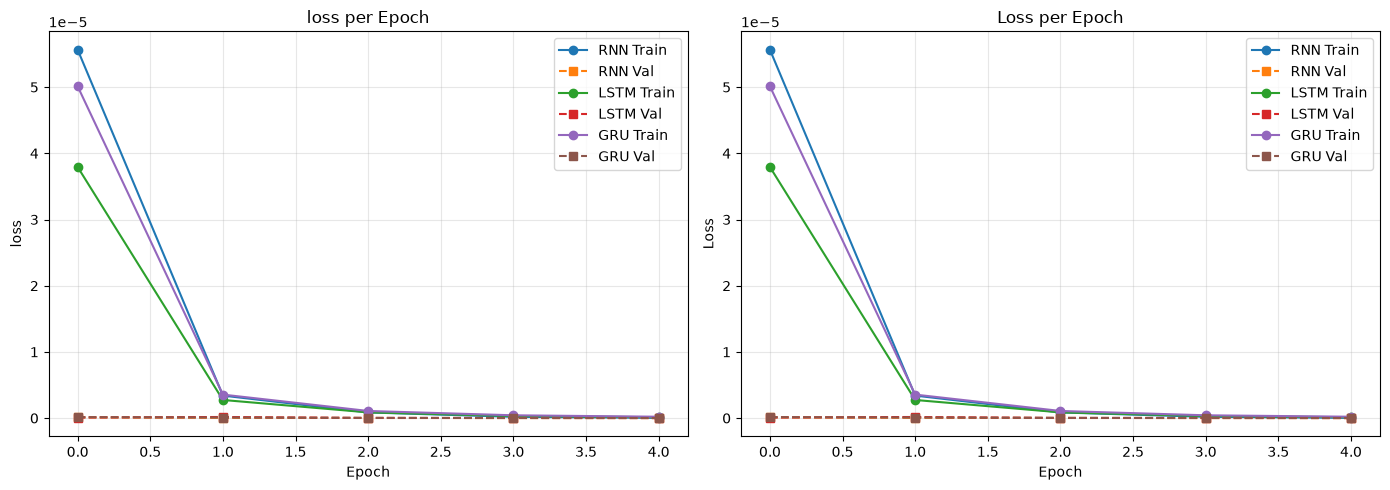

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, history in results.items():
    axes[0].plot(history["train_loss"], marker='o', label=f"{model_name} Train")
    axes[0].plot(history["val_loss"], "--", marker='s', label=f"{model_name} Val")

axes[0].set_title("loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for model_name, history in results.items():
    axes[1].plot(history["train_loss"], marker='o', label=f"{model_name} Train")
    axes[1].plot(history["val_loss"], "--", marker='s', label=f"{model_name} Val")

axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
print("\nRingkasan Hasil:")
print("=" * 60)
print(f"{'Model':<10} | {'Train Loss Akhir':<18} | {'Val Loss Akhir':<18} | {'Jumlah Parameter'}")
print("-" * 60)
for model_name, model in models.items():
    num_params = sum(p.numel() for p in model.parameters())
    final_train_loss = results[model_name]["train_loss"][-1]
    final_val_loss = results[model_name]["val_loss"][-1]
    print(f"{model_name:<10} | {final_train_loss:<18.8f} | {final_val_loss:<18.8f} | {num_params:,}")


Ringkasan Hasil:
Model      | Train Loss Akhir   | Val Loss Akhir     | Jumlah Parameter
------------------------------------------------------------
RNN        | 0.00000003         | 0.00000000         | 801,920
LSTM       | 0.00000013         | 0.00000000         | 1,624,704
GRU        | 0.00000020         | 0.00000001         | 1,394,304
